<a href="https://colab.research.google.com/github/VTKhanhLinh/TH_MachineLearning/blob/main/Tuan1_in_class_Bai1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Bài 1: Gỉa sử có một tập dữ liệu giả định và có các cột Diện tích nhà (m2) và giá bán(vnd)
1. Xây dựng mô hình hồi quy tuyến tính đơn giản dự đoán giá bán dựa trên diện tích.
2. Thêm số lượng dữ liệu và độ nhiễu để xem mô hình hoạt động như thế nào.
3. Thêm các biến đầu vào khác để nâng cao tính phức tạp của mô hình.


1. Xây dựng mô hình hồi quy tuyến tính đơn giản dự đoán giá bán dựa trên diện tích.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

np.random.seed(42)

In [2]:
dien_tich = np.linspace(30, 150, 20)
gia_ban = 300 + 20 * dien_tich + np.random.normal(0, 150, 20)

df = pd.DataFrame({
    "Dien_tich": dien_tich,
    "Gia_ban": gia_ban
})

print(df)

     Dien_tich      Gia_ban
0    30.000000   974.507123
1    36.315789  1005.576144
2    42.631579  1249.784860
3    48.947368  1507.401847
4    55.263158  1370.140152
5    61.578947  1496.458404
6    67.894737  1894.776659
7    74.210526  1899.325736
8    80.526316  1840.105158
9    86.842105  2118.226112
10   93.157895  2093.645241
11   99.473684  2219.614221
12  105.789474  2452.083814
13  112.105263  2255.113226
14  118.421053  2409.683378
15  124.736842  2710.393713
16  131.052632  2769.127964
17  137.368421  3094.505521
18  143.684211  3037.480599
19  150.000000  3088.154445


In [3]:
X = df[["Dien_tich"]]
y = df["Gia_ban"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = LinearRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Hệ số góc:", model.coef_[0])
print("Hệ số chặn:", model.intercept_)
print("MAE:", mean_absolute_error(y_test, y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))
print("R²:", r2_score(y_test, y_pred))

Hệ số góc: 16.514259007667995
Hệ số chặn: 587.4428704806407
MAE: 147.87447175382474
RMSE: 162.46875793112218
R²: 0.971705010963681


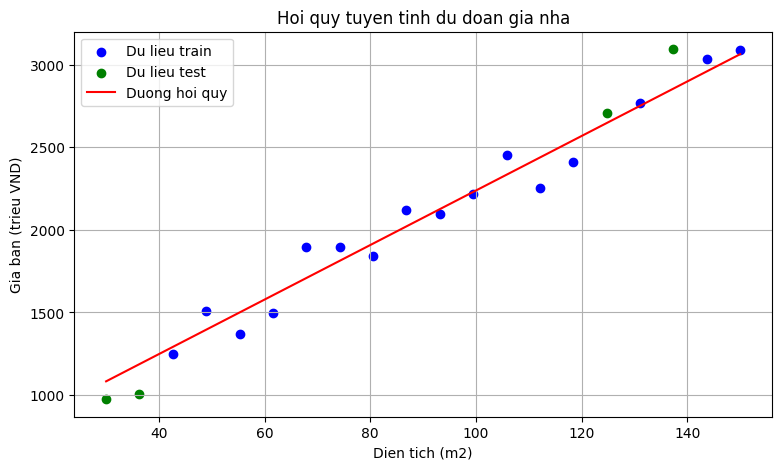

In [4]:
X_line = pd.DataFrame({
    "Dien_tich": np.linspace(30, 150, 100)
})

y_line = model.predict(X_line)

plt.figure(figsize=(9, 5))

plt.scatter(X_train["Dien_tich"], y_train,
            color="blue", label="Du lieu train")

plt.scatter(X_test["Dien_tich"], y_test,
            color="green", label="Du lieu test")

plt.plot(X_line["Dien_tich"], y_line,
         color="red", label="Duong hoi quy")

plt.xlabel("Dien tich (m2)")
plt.ylabel("Gia ban (trieu VND)")
plt.title("Hoi quy tuyen tinh du doan gia nha")
plt.legend()
plt.grid(True)
plt.show()

2. Thêm số lượng dữ liệu và độ nhiễu để xem mô hình hoạt động như thế nào.

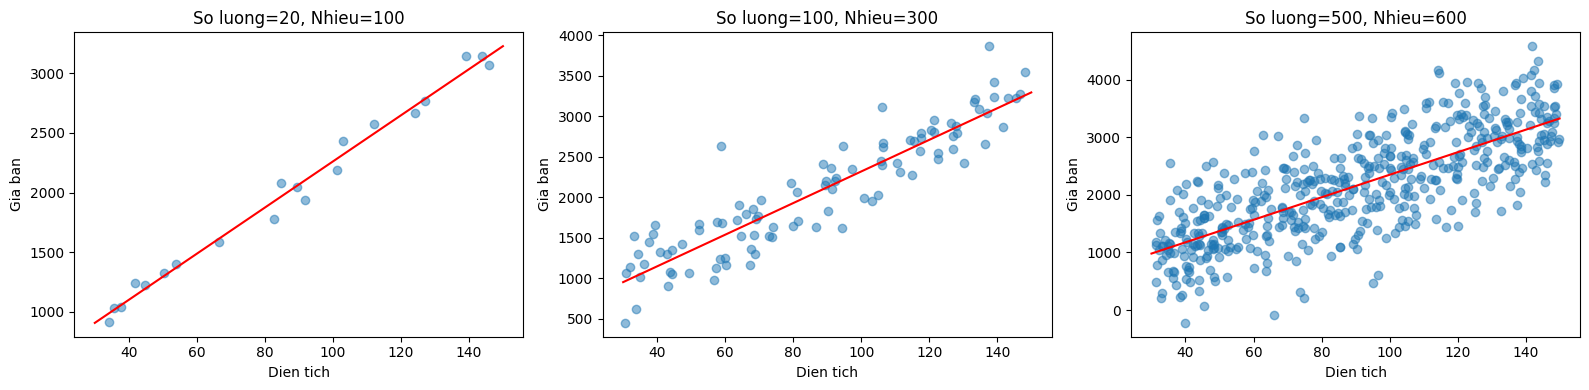

In [5]:
so_luong = [20, 100, 500]
do_nhieu = [100, 300, 600]

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for i in range(3):
    n = so_luong[i]
    noise = do_nhieu[i]

    x = np.random.uniform(30, 150, n)
    y = 300 + 20 * x + np.random.normal(0, noise, n)

    X = x.reshape(-1, 1)

    model_temp = LinearRegression()
    model_temp.fit(X, y)

    x_line = np.linspace(30, 150, 100).reshape(-1, 1)
    y_line = model_temp.predict(x_line)

    axes[i].scatter(x, y, alpha=0.5)
    axes[i].plot(x_line, y_line, color="red")
    axes[i].set_title(f"So luong={n}, Nhieu={noise}")
    axes[i].set_xlabel("Dien tich")
    axes[i].set_ylabel("Gia ban")

plt.tight_layout()
plt.show()

3. Thêm các biến đầu vào khác để nâng cao tính phức tạp của mô hình.


In [6]:
n = 200

dien_tich = np.random.uniform(30, 200, n)
so_phong = np.random.randint(1, 6, n)
tuoi_nha = np.random.randint(0, 31, n)

gia_ban = (
    300
    + 20 * dien_tich
    + 150 * so_phong
    - 15 * tuoi_nha
    + np.random.normal(0, 200, n)
)

df_multi = pd.DataFrame({
    "Dien_tich": dien_tich,
    "So_phong": so_phong,
    "Tuoi_nha": tuoi_nha,
    "Gia_ban": gia_ban
})

print(df_multi.head())

    Dien_tich  So_phong  Tuoi_nha      Gia_ban
0  177.713847         2        10  3790.026117
1  127.003657         5        19  3306.243606
2   35.165800         2        14  1406.063126
3  188.261278         1        18  3695.176265
4  147.219548         5         6  3768.895822


In [7]:
X = df_multi[["Dien_tich", "So_phong", "Tuoi_nha"]]
y = df_multi["Gia_ban"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model_multi = LinearRegression()
model_multi.fit(X_train, y_train)

y_pred = model_multi.predict(X_test)

print("He so:", model_multi.coef_)
print("He so chan:", model_multi.intercept_)
print("MAE:", mean_absolute_error(y_test, y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))
print("R2:", r2_score(y_test, y_pred))

He so: [ 19.91038062 161.24358848 -11.64597507]
He so chan: 215.76722025915524
MAE: 166.3976575885426
RMSE: 207.83844681266038
R2: 0.9576421898548463


In [8]:
nha_moi = pd.DataFrame({
    "Dien_tich": [100],
    "So_phong": [3],
    "Tuoi_nha": [5]
})

gia_du_doan = model_multi.predict(nha_moi)

print(f"Gia nha du doan: {gia_du_doan[0]:,.2f} trieu VND")

Gia nha du doan: 2,632.31 trieu VND
